# Quantile Regression

Median regression estimates the conditional middle of the strength distribution. Absolute and pinball losses are natural ways to judge it.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Estimator

The constructor below fixes the model used in every fold.

In [2]:
import matplotlib.pyplot as plt
from sklearn.linear_model import QuantileRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from gallery.tabular import concrete_split, regression_report

model = make_pipeline(
    StandardScaler(), QuantileRegressor(quantile=0.5, alpha=0.025, solver="highs")
)

## Data and split

All ages of a concrete recipe stay in the same partition. Five training folds also keep recipes together. The final test uses unseen mixes.

In [3]:
X, X_test, y, y_test, groups = concrete_split()

## Held-out predictions

The table includes a training-only baseline. Both panels use the untouched test observations.

Training: 824 observations across 341 recipes. Test: 206 observations.
Training folds, mean R² 0.569, MAE 8.48 MPa
                  R²  MAE (MPa)  RMSE (MPa)  Median AE (MPa)  Bias, pred − obs (MPa)
Model          0.596      8.771      10.958            7.955                  -1.105
Training mean -0.002     14.236      17.267           13.145                  -0.829
Median pinball loss: 4.386 MPa
Fraction below fitted median: 0.432


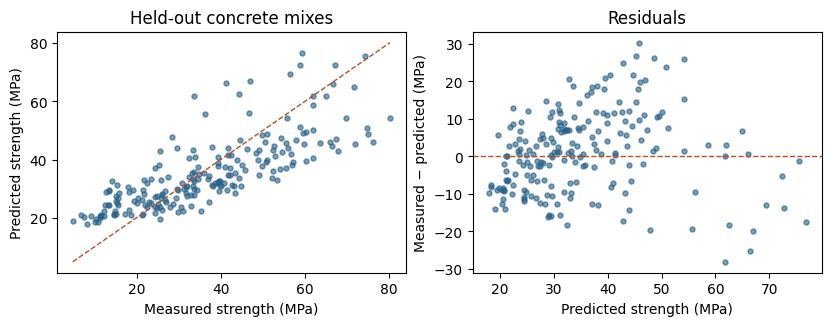

In [4]:
predictions = regression_report(model, X, X_test, y, y_test, groups)
from sklearn.metrics import mean_pinball_loss

print(f"Median pinball loss: {mean_pinball_loss(y_test, predictions, alpha=0.5):.3f} MPa")
print(f"Fraction below fitted median: {(y_test <= predictions).mean():.3f}")
plt.show()

## Reading the result

Compare the fraction of observations below the predicted median with one half. It need not equal one half on a fresh test set.

## References

[scikit-learn, QuantileRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.QuantileRegressor.html)

[I-Cheng Yeh, Concrete Compressive Strength (UCI), CC BY 4.0](https://doi.org/10.24432/C5PK67)